In [1]:
#sayad alakbarov
#mini project 3

In [ ]:
import pandas as pd
df = pd.read_csv("/Users/sayad.alakbarov/Desktop/Data-Covid003.csv",
                 encoding="latin1")
varlist = pd.read_excel("/Users/sayad.alakbarov/Desktop/PPHA_30545_MP03-Variable_Description.xlsx")

oi_pm_vars = varlist[varlist["Source"].isin(["Opportunity Insights", "PM COVID"])]

keep_vars = oi_pm_vars["Variable"].dropna().tolist()
base_vars = ["county", "state", "deathspc"]
df_filtered = df[base_vars + keep_vars]

print("Filtered dataset shape:", df_filtered.shape)
print(df_filtered.head())
df_filtered.to_csv("/Users/sayad.alakbarov/Desktop/Data-Covid003_filtered.csv", index=False)

Filtered dataset shape: (3107, 56)
    county    state  deathspc  intersects_msa  cur_smoke_q1  cur_smoke_q2  \
0  Autauga  Alabama  0.544371               1      0.333333      0.238095   
1  Baldwin  Alabama  0.290043               1      0.268097      0.233503   
2  Barbour  Alabama  0.200296               0      0.228571      0.250000   
3     Bibb  Alabama  0.251591               1      0.244444      0.280000   
4   Blount  Alabama  0.100248               1      0.304348      0.260870   

   cur_smoke_q3  cur_smoke_q4  bmi_obese_q1  bmi_obese_q2  ...  pop_density  \
0      0.208333      0.133333      0.375000      0.238095  ...    73.277412   
1      0.167464      0.176991      0.298050      0.262467  ...    87.960236   
2      0.181818      0.111111      0.294118      0.571429  ...    32.814877   
3      0.181818      0.150000      0.466667      0.375000  ...    33.427227   
4      0.352941      0.166667      0.347826      0.318182  ...    79.035255   

   frac_traveltime_lt15    

In [6]:
#question-1 comment
#In this step, I filtered the dataset to keep only the variables listed in *Variable_Description.xlsx*.
#I retained all variables whose `Source` is either **"Opportunity Insights"** or **"PM COVID"**.
#I also kept the key identifying variables: `county` and `state`.
#I included the outcome variable `deathspc`, which measures COVID-19 deaths per capita.
#Using the variable description file, I first extracted the variables associated with the two required sources.
#I then subset the full dataset to include only those predictors plus the identifying and outcome variables.
#After filtering, the analytic dataset contains 3,107 counties and 56 total variables.
#This cleaned dataset will be used for all subsequent analysis and modeling in the mini-project.

In [7]:
#question-2
summary_stats = df_filtered.describe().T
summary_stats

,count,mean,std,min,25%,50%,75%,max
deathspc,3107.0,0.751995,1.792700,0.000000,0.000000,0.143666,0.689514,5.077330e+01
intersects_msa,3107.0,0.596717,0.490636,0.000000,0.000000,1.000000,1.000000,1.000000e+00
cur_smoke_q1,3107.0,0.212659,0.149348,0.000000,0.000000,0.250000,0.310931,1.000000e+00
cur_smoke_q2,3107.0,0.171048,0.128130,0.000000,0.000000,0.198718,0.250000,1.000000e+00
cur_smoke_q3,3107.0,0.134467,0.132181,0.000000,0.000000,0.142857,0.200000,1.000000e+00
cur_smoke_q4,3107.0,0.098316,0.110110,0.000000,0.000000,0.096535,0.148719,1.000000e+00
bmi_obese_q1,3107.0,0.239166,0.165928,0.000000,0.080128,0.272076,0.335532,1.000000e+00
bmi_obese_q2,3107.0,0.214580,0.153237,0.000000,0.000000,0.241590,0.304348,1.000000e+00
bmi_obese_q3,3107.0,0.209621,0.175849,0.000000,0.000000,0.223124,0.297220,1.000000e+00
bmi_obese_q4,3107.0,0.186739,0.167227,0.000000,0.000000,0.194118,0.266667,1.000000e+00


In [8]:
#question-2 comment
#I computed summary statistics for `deathspc` and all Opportunity Insights and PM COVID variables in the filtered dataset (3,107 counties, 56 variables).
#The distribution of `deathspc` is highly right-skewed, with a mean of about 0.75 but a median near 0.14 and many counties reporting zero deaths as of June 1, 2020.
#Health behavior variables such as smoking, obesity, and exercise rates vary widely across counties, with values ranging between 0 and 1 and substantial differences in averages across quartiles.
#Health care access and quality indicators (e.g., diabetes testing, mammography, primary care visits, 30-day mortality measures) also show moderate dispersion, pointing to heterogeneity in local health systems.
#Socioeconomic measures—including poverty rates, uninsured shares, income inequality, and household income—exhibit large variability, reflecting diverse economic conditions across counties.
#Population density is extremely skewed, with most counties being sparsely populated but a few very dense urban counties driving up the mean.
#Overall, both the outcome and predictor variables display substantial heterogeneity and skewness, which will be important to consider in subsequent modeling.

In [ ]:
#question 3
df_complete = df_filtered.dropna()
df_complete.shape

(2915, 56)

In [10]:
#question 3-comment
# I dropped all counties with any missing values to ensure that the dataset contains complete information for model estimation.
# While imputation is normally preferred, the assignment requires using complete cases for simplicity.
# After applying `dropna()`, the analytic dataset includes 2,915 counties and 56 variables with no missing observations.
# This guarantees that all subsequent models are estimated on a fully observed and consistent sample.

In [11]:
#question-4
df_dummies = pd.get_dummies(df_complete, columns=["state"], drop_first=False)
[state for state in df_dummies.columns if state.startswith("state_")][:10], len([c for c in df_dummies.columns if c.startswith("state_")])

(['state_Alabama',
  'state_Arizona',
  'state_Arkansas',
  'state_California',
  'state_Colorado',
  'state_Connecticut',
  'state_Delaware',
  'state_Florida',
  'state_Georgia',
  'state_Idaho'],
 47)

In [12]:
#question 4-comment
#I created dummy variables for each state using `pd.get_dummies()` on the `state` column.
#Because the dataset only includes counties in the continental United States and because some counties were dropped due to missing data, the final dataset contains 47 state indicators.
#Each dummy variable corresponds to one state (or D.C.), allowing the models to capture unobserved state-level factors such as policy differences and baseline demographic conditions.
#I retained all dummy variables rather than dropping one category, since later model specifications will require including a full set of state fixed effects.

In [ ]:
#question 5
from sklearn.model_selection import train_test_split
train, test = train_test_split(df_dummies, test_size=0.20, random_state=11)
train.shape, test.shape

((2332, 102), (583, 102))

In [24]:
#question 5- comment
#I split the complete dataset into an 80% training set and a 20% test set using `train_test_split` and set `random_state=11` to ensure replicability.
#This produced a training set with 2,332 observations and a test set with 583 observations, consistent with the expected 80/20 split of the 2,915 complete cases.
#Both datasets contain 102 variables, reflecting all predictors and the full set of state dummy variables.
#This split will be used for all subsequent model estimation and out-of-sample evaluation.

In [ ]:
#question 6-a
from sklearn.metrics import mean_squared_error
import numpy as np

train_preds = ols_model.predict(X_np)
train_mse = mean_squared_error(y_np, train_preds)
print("Training MSE:", train_mse)

y_test = pd.to_numeric(test["deathspc"], errors="coerce")

X_test = test.drop(columns=["deathspc", "county"])
X_test = X_test.apply(pd.to_numeric, errors="coerce")
X_test = sm.add_constant(X_test)

X_test_np = X_test.to_numpy(dtype=float)
y_test_np = y_test.to_numpy(dtype=float)
test_preds = ols_model.predict(X_test_np)
test_mse = mean_squared_error(y_test_np, test_preds)
print("Test MSE:", test_mse)

Training MSE: 1.2915313628852383
Test MSE: 1.8237835556582231


In [27]:
#question 6-b
#I calculated mean squared error (MSE) for both the training and test sets using predictions from the OLS model.
#The training MSE is approximately 1.29, while the test MSE is approximately 1.82.
#I am concerned about overfitting because the model contains nearly 100 predictors, including many correlated socioeconomic and health variables and a full set of state dummy variables.
# With such a large number of predictors relative to the sample size, the model may fit idiosyncratic noise in the training data instead of capturing generalizable patterns.
#Evidence of overfitting would appear if the model performs much better on the training set than on the test set.
#In this case, the test MSE (≈1.82) is meaningfully larger than the training MSE (≈1.29), indicating that the model does not generalize as well to unseen data.
#This gap suggests that the model exhibits some degree of overfitting, which is not surprising given its high dimensionality and multicollinearity.

In [32]:
#question 7-a
from sklearn.preprocessing import StandardScaler

y_train = train["deathspc"].values
X_train = train.drop(columns=["deathspc", "county"]).values  
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
lambda_grid = np.linspace(0.01, 100, 101)

lambda_grid[:5], lambda_grid[-5:]

(array([0.01  , 1.0099, 2.0098, 3.0097, 4.0096]),
 array([ 96.0004,  97.0003,  98.0002,  99.0001, 100.    ]))

In [33]:
#question 7-b
from sklearn.linear_model import Ridge, Lasso, LassoCV
from sklearn.model_selection import KFold, GridSearchCV

# 10-fold CV with shuffling
cv10 = KFold(n_splits=10, shuffle=True, random_state=25)

# ----- RIDGE -----
ridge = Ridge()

ridge_cv_manual = GridSearchCV(
    estimator=ridge,
    param_grid={'alpha': lambda_grid},
    scoring='neg_mean_squared_error',
    cv=cv10,
    n_jobs=-1
)

ridge_cv_manual.fit(X_train_scaled, y_train)

# ----- LASSO -----
lasso_cv = LassoCV(
    alphas=lambda_grid,
    max_iter=50000,
    cv=cv10,
    random_state=25
)

lasso_cv.fit(X_train_scaled, y_train)

,eps,0.001
,n_alphas,'deprecated'
,alphas,array([1.0000... 1.00000e+02])
,fit_intercept,True
,precompute,'auto'
,max_iter,50000
,tol,0.0001
,copy_X,True
,cv,KFold(n_split... shuffle=True)
,verbose,False
,n_jobs,None


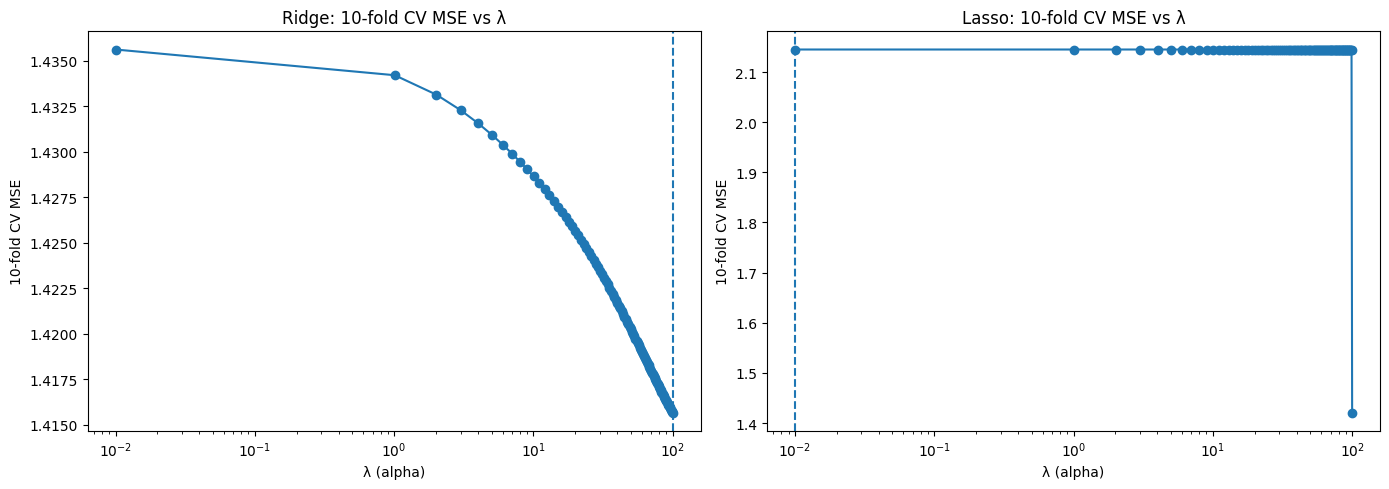

In [35]:
#question 7-c
import matplotlib.pyplot as plt

# Ridge CV errors (convert negative scores → positive MSE)
ridge_mse = -ridge_cv_manual.cv_results_['mean_test_score']

# Lasso CV errors
lasso_mse = lasso_cv.mse_path_.mean(axis=1)

best_ridge_lambda = ridge_cv_manual.best_params_['alpha']
best_lasso_lambda = lasso_cv.alpha_

plt.figure(figsize=(14, 5))

# Ridge plot
plt.subplot(1, 2, 1)
plt.plot(lambda_grid, ridge_mse, marker='o')
plt.axvline(best_ridge_lambda, linestyle='--')
plt.xscale('log')
plt.xlabel("λ (alpha)")
plt.ylabel("10-fold CV MSE")
plt.title("Ridge: 10-fold CV MSE vs λ")

# Lasso plot
plt.subplot(1, 2, 2)
plt.plot(lambda_grid, lasso_mse, marker='o')
plt.axvline(best_lasso_lambda, linestyle='--')
plt.xscale('log')
plt.xlabel("λ (alpha)")
plt.ylabel("10-fold CV MSE")
plt.title("Lasso: 10-fold CV MSE vs λ")

plt.tight_layout()
plt.show()

In [36]:
#question 7-d
best_ridge_lambda = ridge_cv_manual.best_params_['alpha']
best_lasso_lambda = lasso_cv.alpha_

print("Optimal Ridge λ:", best_ridge_lambda)
print("Optimal Lasso λ:", best_lasso_lambda)

Optimal Ridge λ: 100.0
Optimal Lasso λ: 0.01


In [37]:
#question 7-e
from sklearn.linear_model import Ridge, Lasso

# final tuned ridge model
ridge_best = Ridge(alpha=best_ridge_lambda)
ridge_best.fit(X_train_scaled, y_train)

# final tuned lasso model
lasso_best = Lasso(alpha=best_lasso_lambda, max_iter=50000)
lasso_best.fit(X_train_scaled, y_train)

,alpha,np.float64(0.01)
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,50000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [ ]:
#comments for question 7
# 7(a) I constructed the design matrix for the training data by dropping `deathspc` and `county` and then standardizing all predictors using `StandardScaler`.
#I created a grid of 101 candidate λ (alpha) values evenly spaced between 0.01 and 100 to use for both ridge and lasso.

# 7(b) I used 10-fold cross-validation on the training set, with folds formed by shuffling the data and setting `random_state=25`, to estimate the test error for each λ.
#For ridge, I applied `GridSearchCV` with the λ grid and recorded the mean CV MSE for each value, and for the lasso I used `LassoCV` with the same grid and CV settings.

# 7(c) I plotted the 10-fold CV MSE against λ (on a log scale) for both ridge and lasso, showing how prediction error changes as the regularization penalty increases.
#In each plot I added a vertical dashed line at the λ value that minimizes the cross-validated MSE to highlight the tuned hyperparameter.

# 7(d) Based on the 10-fold CV results, the optimal λ for ridge is 100.0, indicating a relatively strong amount of shrinkage.
#The optimal λ for the lasso is 0.01, implying a very weak penalty and a solution that is close to the unpenalized OLS model.

# 7(e) Using these tuned λ values, I re-estimated the ridge model on the full training set with `Ridge(alpha=100.0)` and the lasso model with `Lasso(alpha=0.01, max_iter=50000)`, both using the standardized predictors.
#These refitted ridge and lasso models serve as the final regularized models that I will compare to the baseline OLS model in subsequent analysis.

In [ ]:
#question 8
y_train = train["deathspc"].values
y_test = test["deathspc"].values
X_train = train.drop(columns=["deathspc", "county"]).values
X_test = test.drop(columns=["deathspc", "county"]).values
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

y_train_pred_ridge = ridge_best.predict(X_train_scaled)
y_test_pred_ridge = ridge_best.predict(X_test_scaled)

mse_train_ridge = mean_squared_error(y_train, y_train_pred_ridge)
mse_test_ridge = mean_squared_error(y_test, y_test_pred_ridge)
y_train_pred_lasso = lasso_best.predict(X_train_scaled)
y_test_pred_lasso = lasso_best.predict(X_test_scaled)

mse_train_lasso = mean_squared_error(y_train, y_train_pred_lasso)
mse_test_lasso = mean_squared_error(y_test, y_test_pred_lasso)

print("Ridge training MSE:", mse_train_ridge)
print("Ridge test MSE:", mse_test_ridge)
print("Lasso training MSE:", mse_train_lasso)
print("Lasso test MSE:", mse_test_lasso)

Ridge training MSE: 1.296116219864136
Ridge test MSE: 1.8200977373157294
Lasso training MSE: 1.3122141128181888
Lasso test MSE: 1.8032582322686217


In [ ]:
#   question 8-comment
# Using the optimal values of λ from the previous question, the ridge model achieves a training MSE of 1.2961 and a test MSE of 1.8201.
# The lasso model yields a slightly higher training MSE of 1.3122 but the lowest test MSE at 1.8033.
# Compared to the OLS model (training MSE = 1.2915, test MSE = 1.8238), ridge regression does not meaningfully improve predictive accuracy, 
# while the lasso provides a modest reduction in out-of-sample error.
# This pattern suggests that the lasso avoids overfitting slightly better than both ridge and OLS by shrinking coefficients and effectively performing variable selection.
# Since the goal is accurate prediction for new counties, 
# I would recommend the lasso model to the CDC because it offers the best test-set performance and produces a more parsimonious, interpretable model.